# Analysis of Results Common
Comparing individual `_best.csv` files against concatenated batch results, followed by LabelFree Validation.

In [1]:
import pandas as pd
import glob
import os
import numpy as np
import ast
from scipy.stats import pearsonr, zscore
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd # Ensure pandas is avail


In [2]:


RESULTS_DIR = "../results_val"


## 1. Load Individual `*_best.csv` Files

In [3]:

# Find all protein_best.csv files
best_files = glob.glob(os.path.join(RESULTS_DIR, "*_best.csv"))
print(f"Found {len(best_files)} individual best files.")

dfs = []
for f in best_files:
    try:
        df = pd.read_csv(f)
        dfs.append(df)
    except Exception as e:
        print(f"Error reading {f}: {e}")

if dfs:
    df_best_all = pd.concat(dfs, ignore_index=True)
    # Sort for consistency
    df_best_all.sort_values("protein", inplace=True)
    df_best_all.reset_index(drop=True, inplace=True)
    
    print(f"Concatenated Best Shape: {df_best_all.shape}")
    display(df_best_all.head())
else:
    df_best_all = pd.DataFrame()
    print("No best files loaded.")


Found 1809 individual best files.
Concatenated Best Shape: (1809, 10)


,protein,best_sample,best_abs_error,mse_all_others,params_dict,feat_coeffs_dict,zscore_genes,zscore_mu,zscore_sigma,zscore_eps
0,A2M,UMUC3_URINARY_TRACT,0.003011,0.836941,"{'alpha': 1.0, 'l1_ratio': 0.1}","{'A1BG': 0.0, 'A2M': 0.05601153568687824, 'AAD...","['A1BG', 'A2M', 'AADAT', 'AASS', 'ABCB6', 'ABI...","[2.821546846143207, 0.8868445119261132, 2.2698...","[2.051967442561821, 1.8051704733585499, 1.2569...",1.000000e-08
1,AARS2,SQ1_LUNG,0.000137,0.140420,"{'alpha': 0.1, 'l1_ratio': 0.5}","{'A2M': 0.0, 'AARS2': 0.15406732440684603, 'AA...","['A2M', 'AARS2', 'AATK', 'ABCC10', 'ABCG1', 'A...","[0.8871246572874287, 3.4942220091470135, 1.098...","[1.8050580488255072, 0.6163178413829652, 1.117...",1.000000e-08
2,AASDHPPT,HEC59_ENDOMETRIUM,0.000364,0.273664,"{'alpha': 0.1, 'l1_ratio': 0.9}","{'A4GALT': -0.0, 'AAAS': 0.0, 'AARS2': 0.0, 'A...","['A4GALT', 'AAAS', 'AARS2', 'AASDHPPT', 'ABCB1...","[2.103931763318877, 5.69152738256317, 3.493995...","[1.5504930921286346, 0.5083307393271205, 0.616...",1.000000e-08
3,ABCB7,SEM_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.000245,0.147214,"{'alpha': 0.1, 'l1_ratio': 0.5}","{'AASS': -0.0, 'ABCB6': -0.0, 'ABCB7': 0.22758...","['AASS', 'ABCB6', 'ABCB7', 'ABI3', 'ABL1', 'AC...","[2.029682970399025, 4.270079436520009, 4.11333...","[1.4572810773960054, 1.3446260392182268, 0.563...",1.000000e-08
4,ABCD3,CAL33_UPPER_AERODIGESTIVE_TRACT,0.000973,0.202043,"{'alpha': 0.1, 'l1_ratio': 0.5}","{'AAAS': -0.0, 'AASDHPPT': -0.0118042086846440...","['AAAS', 'AASDHPPT', 'ABCC3', 'ABCC6', 'ABCD3'...","[5.692029499779636, 4.809574950496353, 3.54140...","[0.5086774092766796, 0.610410849672823, 2.4961...",1.000000e-08


## 2. Load Batch Result Files

In [4]:

# Find batch files (assuming pattern results_batch_*.csv)
batch_files = glob.glob(os.path.join(RESULTS_DIR, "*batch*.csv"))
print(f"Found {len(batch_files)} batch files.")

dfs_batch = []
for f in batch_files:
    try:
        df = pd.read_csv(f)
        dfs_batch.append(df)
    except Exception as e:
        print(f"Error reading {f}: {e}")

if dfs_batch:
    df_batch_concat = pd.concat(dfs_batch, ignore_index=True)
    df_batch_concat.sort_values("protein", inplace=True)
    df_batch_concat.reset_index(drop=True, inplace=True)
    
    print(f"Concatenated Batch Shape: {df_batch_concat.shape}")
    display(df_batch_concat.head())
else:
    df_batch_concat = pd.DataFrame()
    print("No batch files loaded.")


Found 0 batch files.
No batch files loaded.


## 3. Compare

In [5]:

# Check if they are the same
if not df_best_all.empty and not df_batch_concat.empty:
    # 1. Compare protein lists
    prots_best = set(df_best_all['protein'].unique())
    prots_batch = set(df_batch_concat['protein'].unique())
    
    missing_in_batch = prots_best - prots_batch
    missing_in_best = prots_batch - prots_best
    
    print(f"Proteins in Best: {len(prots_best)}")
    print(f"Proteins in Batch: {len(prots_batch)}")
    
    if missing_in_batch:
        print(f"Proteins in Best but NOT in Batch: {len(missing_in_batch)}")
    if missing_in_best:
        print(f"Proteins in Batch but NOT in Best: {len(missing_in_best)}")
        
    # Check shape equality
    if df_best_all.shape == df_batch_concat.shape:
         try:
            pd.testing.assert_frame_equal(df_best_all, df_batch_concat, check_like=True)
            print("SUCCESS: DataFrames are identical (pd.testing.assert_frame_equal passed).")
         except AssertionError as e:
            print(f"DataFrames are NOT identical: {e}")
    else:
        print("Shapes differ, cannot be identical.")

else:
    print("Cannot compare - one or both dataframes are empty.")


Cannot compare - one or both dataframes are empty.


## 4. LabelFree Data Loading (Pre-Processed with Gene Symbols)

In [6]:


# --- UPDATED: Load from Validation Folder ---
RNA_PATH = "../val_data/LabelFree_transcriptomics.joblib"
PROT_PATH = "../val_data/LabelFree_proteomics.joblib"

print(f"Loading Validation LabelFree Data from: {RNA_PATH} and {PROT_PATH}")

rna_df = None
prot_df = None

if os.path.exists(RNA_PATH) and os.path.exists(PROT_PATH):
    try:
        rna_df = joblib.load(RNA_PATH)
        prot_df = joblib.load(PROT_PATH)
        
        # Ensure we have pandas DataFrames
        if not isinstance(rna_df, pd.DataFrame):
            print("Warning: Loaded RNA object is not a DataFrame.")
        if not isinstance(prot_df, pd.DataFrame):
            print("Warning: Loaded Protein object is not a DataFrame.")

        print(f"LabelFree RNA Shape: {rna_df.shape}")
        print(f"LabelFree Protein Shape: {prot_df.shape}")
        
        # Display heads if possible (requires IPython display which is avail in notebook)
        try:
            display(rna_df.head())
            display(prot_df.head())
        except:
            print(rna_df.head())
            print(prot_df.head())
        
    except Exception as e:
        print(f"Error loading joblib files: {e}")
else:
    print(f"Validation files not found. Current CWD: {os.getcwd()}")
    if not os.path.exists("../validation"):
        print("Folder ../validation does not exist.")


Loading Validation LabelFree Data from: ../val_data/LabelFree_transcriptomics.joblib and ../val_data/LabelFree_proteomics.joblib
LabelFree RNA Shape: (360, 14947)
LabelFree Protein Shape: (360, 2563)


,A1BG,A1CF,A2LD1,A2M,A4GALT,AAAS,AACS,AADAT,AAGAB,AAK1,...,ZW10,ZWILCH,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11B,ZYX,ZZEF1,ZZZ3
BRAIN_1,-0.035243,NaN,-1.078980,-0.025720,NaN,-0.653872,-0.331334,-0.198950,1.018361,-0.558240,...,-1.289516,-0.030164,-0.369982,-0.637403,-0.205629,-2.373387,1.256787,0.056197,-2.248267,-1.206728
BRAIN_2,-0.202225,NaN,-0.992947,-0.034372,NaN,0.477955,-1.468399,-1.762339,1.141021,-0.247318,...,-0.308009,-0.191297,-1.646210,-0.424113,-0.182773,-1.063564,1.146739,1.824459,-0.931793,-1.123193
BRAIN_3,0.026598,NaN,-1.123610,-0.104239,NaN,-1.012819,-0.187933,-0.560335,0.707054,-0.686187,...,-2.710417,-0.910448,-0.993978,-1.091420,-1.693233,-2.850774,0.518439,-0.262456,-3.012176,-1.862266
BRAIN_4,-0.666819,NaN,-1.139074,0.287703,NaN,-0.749781,-0.148811,-0.884961,2.261960,0.572822,...,-0.412311,-0.621193,0.249116,-0.793385,0.010546,-2.223451,1.755981,-0.043558,-1.180206,-0.965563
BRAIN_5,-0.290369,NaN,-0.871852,0.172489,NaN,-0.447751,-0.976267,-0.219137,1.188767,-0.605354,...,-0.659919,-0.542667,-0.523034,-0.601878,-0.572359,-2.050073,0.519055,-0.687763,-2.079273,-1.185158


,A1BG,A2M,AARS1,AARS2,AASDHPPT,ABAT,ABCB7,ABCD3,ABCE1,ABCF1,...,YWHAQ,YWHAZ,ZC3H15,ZC3HAV1,ZFR,ZMPSTE24,ZNF207,ZW10,ZYX,ZZEF1
BRAIN_1,6.98,9.435,9.745,7.422,8.581,10.012,6.823,8.329,8.591,7.380,...,10.229,10.932,6.982,NaN,7.000,7.935,7.035,7.435,8.098,7.567
BRAIN_2,6.98,9.790,9.747,7.852,8.584,10.301,7.927,8.948,8.481,8.053,...,10.416,10.698,6.982,NaN,8.187,7.665,8.568,7.599,8.641,7.569
BRAIN_3,6.98,9.794,9.816,7.706,8.695,9.891,7.827,8.781,8.706,8.444,...,10.215,10.946,7.768,NaN,7.000,7.910,7.035,7.830,8.226,7.615
BRAIN_4,6.98,9.633,9.712,7.676,8.641,10.365,7.727,8.860,8.228,8.164,...,10.155,10.849,6.982,NaN,7.000,8.016,7.035,7.774,8.294,7.639
BRAIN_5,6.98,9.631,9.790,7.770,9.113,10.262,7.893,8.639,8.248,8.169,...,10.104,10.918,7.737,NaN,7.000,8.031,7.817,7.912,8.098,7.641


## 5. Check Features & Normalize

In [7]:

if rna_df is not None:
    # 1. SKIP Normalization (Data already normalized) - Just handle NaNs
    print("Skipping z-score normalization (data already normalized). Filling NaNs with 0...")
    
    # Just fill NaNs (crucial to prevent NaNs in prediction)
    rna_z = rna_df.fillna(0)
    
    print("NaNs filled with 0.")
    display(rna_z.head())
    
    # Check coverage
    if not df_best_all.empty:
        import ast
        example_coeffs = ast.literal_eval(df_best_all.iloc[0]['feat_coeffs_dict'])
        needed = list(example_coeffs.keys())
        present = [g for g in needed if g in rna_z.columns]
        print(f"Example Model ({df_best_all.iloc[0]['protein']}) feature coverage: {len(present)}/{len(needed)}")


Skipping z-score normalization (data already normalized). Filling NaNs with 0...
NaNs filled with 0.


,A1BG,A1CF,A2LD1,A2M,A4GALT,AAAS,AACS,AADAT,AAGAB,AAK1,...,ZW10,ZWILCH,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11B,ZYX,ZZEF1,ZZZ3
BRAIN_1,-0.035243,0.0,-1.078980,-0.025720,0.0,-0.653872,-0.331334,-0.198950,1.018361,-0.558240,...,-1.289516,-0.030164,-0.369982,-0.637403,-0.205629,-2.373387,1.256787,0.056197,-2.248267,-1.206728
BRAIN_2,-0.202225,0.0,-0.992947,-0.034372,0.0,0.477955,-1.468399,-1.762339,1.141021,-0.247318,...,-0.308009,-0.191297,-1.646210,-0.424113,-0.182773,-1.063564,1.146739,1.824459,-0.931793,-1.123193
BRAIN_3,0.026598,0.0,-1.123610,-0.104239,0.0,-1.012819,-0.187933,-0.560335,0.707054,-0.686187,...,-2.710417,-0.910448,-0.993978,-1.091420,-1.693233,-2.850774,0.518439,-0.262456,-3.012176,-1.862266
BRAIN_4,-0.666819,0.0,-1.139074,0.287703,0.0,-0.749781,-0.148811,-0.884961,2.261960,0.572822,...,-0.412311,-0.621193,0.249116,-0.793385,0.010546,-2.223451,1.755981,-0.043558,-1.180206,-0.965563
BRAIN_5,-0.290369,0.0,-0.871852,0.172489,0.0,-0.447751,-0.976267,-0.219137,1.188767,-0.605354,...,-0.659919,-0.542667,-0.523034,-0.601878,-0.572359,-2.050073,0.519055,-0.687763,-2.079273,-1.185158


Example Model (A2M) feature coverage: 1194/1194


In [8]:

# 5.5 Setting up Analysis
print("\n=======================================================")
print(" PART 1: Analysis with ALL Tissues (No Filtering) ")
print("=======================================================\n")

# Note: Filtering will be done in Part 2 below.



 PART 1: Analysis with ALL Tissues (No Filtering) 



In [9]:

# --- CHECK PERCENTAGE OF ZEROS PER TISSUE ---
if 'rna_z' in locals() and not rna_z.empty:
    print("\n--- Percentage of Zeros per Tissue (RNA Data) ---")
    
    # Helper to get tissue from index (if not already defined)
    def get_tissue_check(idx):
        parts = idx.rsplit('_', 1)
        if len(parts) == 2 and parts[1].isdigit():
            return parts[0]
        return idx
    
    rna_zeros = rna_z.copy()
    rna_zeros['Tissue'] = [get_tissue_check(x) for x in rna_zeros.index]
    
    # Calculate % zeros: (Count of 0s / Total Cells) * 100
    zero_stats = rna_zeros.groupby('Tissue').apply(lambda x: (x.drop(columns='Tissue') == 0).sum().sum() / x.drop(columns='Tissue').size * 100)
    
    display(zero_stats.sort_values(ascending=False).to_frame(name="% Zeros"))
else:
    print("rna_z not found. Cannot check zeros.")
# --------------------------------------------



--- Percentage of Zeros per Tissue (RNA Data) ---


C:\Users\hp\AppData\Local\Temp\ipykernel_31296\1257190750.py:16: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  zero_stats = rna_zeros.groupby('Tissue').apply(lambda x: (x.drop(columns='Tissue') == 0).sum().sum() / x.drop(columns='Tissue').size * 100)


,% Zeros
Tissue,
LIVER,14.042952
BRAIN,10.671038
COLON,8.717468
PROSTATE,5.044491
LUNG,2.334917


## 6. Predict LabelFree Proteins & Evaluate

In [10]:

# --- DEBUG: Feature Overlap Check ---
if rna_df is not None and not df_best_all.empty:
    print("Debugging Feature Coverage...")
    rna_feats = set(rna_df.columns)
    print(f"Total LabelFree RNA Features: {len(rna_feats)}")
    
    # Check first 5 models
    for idx, row in df_best_all.head(5).iterrows():
        p_name = row['protein']
        coeffs = ast.literal_eval(row['feat_coeffs_dict'])
        needed = set(coeffs.keys())
        
        missing = needed - rna_feats
        present = needed & rna_feats
        
        print(f"Protein {p_name}: Needed {len(needed)}, Present {len(present)}, Missing {len(missing)}")
        if missing:
            print(f"  -> First 3 missing: {list(missing)[:3]}")
else:
    print("Data not loaded.")
# ------------------------------------


Debugging Feature Coverage...
Total LabelFree RNA Features: 14947
Protein A2M: Needed 1194, Present 1194, Missing 0
Protein AARS2: Needed 1194, Present 1194, Missing 0
Protein AASDHPPT: Needed 1194, Present 1194, Missing 0
Protein ABCB7: Needed 1194, Present 1194, Missing 0
Protein ABCD3: Needed 1194, Present 1194, Missing 0


In [11]:

results = []
error_dict = {} # Key: Protein, Value: Series of errors (index=Sample)

if rna_df is not None and not df_best_all.empty:
    for idx, row in df_best_all.iterrows():
        p_name = row['protein']
        coeffs = ast.literal_eval(row['feat_coeffs_dict'])
        needed_feats = list(coeffs.keys())
        
        # Check target
        target_present = False
        y_true = None
        if p_name in prot_df.columns:
            target_present = True
            y_true = prot_df[p_name]
        
        # Check features
        missing = [f for f in needed_feats if f not in rna_z.columns]
        if missing:
            # print(f"Skipping {p_name}: missing {len(missing)} features")
            continue
            
        # Predict
        weights = np.array([coeffs[f] for f in needed_feats])
        X = rna_z[needed_feats]
        
        y_pred = X.dot(weights)
        
        mse = np.nan
        corr = np.nan
        cosine_sim = np.nan
        
        # Calculate Error Vector
        error_vector = None
        
        if target_present:
            common = y_pred.index.intersection(y_true.index)
            if len(common) > 2:
                yp = y_pred.loc[common]
                yt = y_true.loc[common]
                
                # Calculate errors for all common samples
                # error = predicted - actual
                error_vector = yp - yt
                
                valid = (~np.isnan(yp)) & (~np.isnan(yt))
                if valid.sum() > 2:
                    mse = np.mean((yp[valid] - yt[valid])**2)
                    corr, _ = pearsonr(yp[valid], yt[valid])
                    # Cosine Similarity
                    if np.linalg.norm(yp[valid]) > 0 and np.linalg.norm(yt[valid]) > 0:
                        cosine_sim = np.dot(yp[valid], yt[valid]) / (np.linalg.norm(yp[valid]) * np.linalg.norm(yt[valid]))
                    else:
                        cosine_sim = 0.0
        
        # Store error vector if it exists
        if error_vector is not None:
             error_dict[p_name] = error_vector
        
        results.append({
            "Protein": p_name,
            "MSE": mse,
            "Correlation": corr,
            "Cosine_Similarity": cosine_sim,
            "Target_Present": target_present
        })

    results_df = pd.DataFrame(results)
    print(f"Prediction complete for {len(results_df)} proteins.")
    display(results_df.head())
    
    if not results_df.empty:
        print("Average MSE:", results_df['MSE'].mean())
        print("Average Correlation:", results_df['Correlation'].mean())
    if 'Cosine_Similarity' in results_df.columns:
        print("Average Cosine Similarity:", results_df['Cosine_Similarity'].mean())

    # Create Error Table
    if error_dict:
        error_table = pd.DataFrame(error_dict).T # Proteins as Rows, Samples as Columns
        print("\nError Table (Predicted - Actual):")
        display(error_table.head())
    else:
        print("No error data collected.")
else:
    print("Cannot run prediction.")


Prediction complete for 1809 proteins.


,Protein,MSE,Correlation,Cosine_Similarity,Target_Present
0,A2M,496.343381,0.302571,0.143275,True
1,AARS2,389.535275,-0.064905,-0.348892,True
2,AASDHPPT,376.018597,-0.754767,0.328878,True
3,ABCB7,349.918186,0.727181,0.076466,True
4,ABCD3,377.819927,0.261448,0.133823,True


Average MSE: 410.45551034021514
Average Correlation: 0.07926261327972756
Average Cosine Similarity: 0.13602787265154592

Error Table (Predicted - Actual):


,BRAIN_1,BRAIN_2,BRAIN_3,BRAIN_4,BRAIN_5,BRAIN_6,BRAIN_7,BRAIN_8,BRAIN_9,BRAIN_10,...,PROSTATE_56,PROSTATE_57,PROSTATE_58,PROSTATE_59,PROSTATE_60,PROSTATE_61,PROSTATE_62,PROSTATE_63,PROSTATE_64,PROSTATE_65
A2M,-9.074317,-9.356039,-9.466590,-9.235010,-9.283565,-9.242688,-9.149888,-8.975112,-8.899173,-9.314934,...,-32.266642,-32.724893,-32.199675,-31.998735,-32.759182,-32.766940,-33.203988,-32.055208,-32.454243,-34.345174
AARS2,-7.664507,-8.119805,-7.978314,-7.825424,-7.980402,-7.392019,-7.159057,-7.755541,-7.612512,-7.483869,...,-26.049607,-27.047035,-26.866267,-27.131428,-28.092002,-27.673154,-27.013486,-26.676083,-27.020620,-27.094036
AASDHPPT,-8.048881,-8.056119,-8.345965,-7.960286,-8.438644,-7.440005,-8.119608,-8.020256,-8.382367,-8.045016,...,-24.660696,-25.544229,-25.654178,-24.158258,-24.699303,-24.914353,-24.893872,-25.574912,-24.919423,-25.062362
ABCB7,-7.331748,-8.210481,-8.316037,-8.148086,-8.115864,-7.946078,-8.148329,-7.921167,-8.050829,-8.130554,...,-23.097825,-24.164039,-25.152002,-23.876234,-24.425149,-23.930528,-24.159060,-23.995560,-23.687307,-20.769975
ABCD3,-8.093863,-8.912214,-8.728782,-8.627615,-8.544862,-8.098918,-8.288858,-8.938728,-9.180464,-8.551957,...,-27.930482,-28.108007,-28.477206,-28.651214,-27.508173,-27.571838,-28.575728,-28.776340,-28.596391,-26.999306


In [12]:

# 7. Sorted Results & NaN Analysis
if 'results_df' in locals() and not results_df.empty:
    # Remove Target_Present if it exists
    df_display = results_df.copy()
    if "Target_Present" in df_display.columns:
        df_display = df_display.drop(columns=["Target_Present"])
    
    print("\n--- Top 10 by CORRELATION (Descending) ---")
    display(df_display.sort_values(by="Correlation", ascending=False).head(10))
    
    print("\n--- Top 10 by MSE (Ascending) ---")
    display(df_display.sort_values(by="MSE", ascending=True).head(10))
    
    if "Cosine_Similarity" in df_display.columns:
        print("\n--- Top 10 by COSINE SIMILARITY (Descending) ---")
        display(df_display.sort_values(by="Cosine_Similarity", ascending=False).head(10))
else:
    print("No protein results found.")

# Analyze NaNs in Error Table
if 'error_table' in locals() and not error_table.empty:
    total_nans = error_table.isna().sum().sum()
    print(f"\nTotal NaNs in Error Table: {total_nans}")
    
    if total_nans > 0:
        nan_prots = error_table.index[error_table.isna().any(axis=1)].tolist()
        print(f"Proteins with NaNs ({len(nan_prots)}): {nan_prots[:10]} ...")



--- Top 10 by CORRELATION (Descending) ---


,Protein,MSE,Correlation,Cosine_Similarity
1163,PPP4C,217.977938,0.967410,0.621896
1324,RP2,415.903703,0.950637,0.311467
152,ARFGAP2,146.753920,0.948726,0.732048
992,NLRX1,383.068458,0.948372,0.254685
1132,POLR2B,313.389916,0.938731,0.597866
1490,SLMAP,456.663078,0.935646,0.245933
838,LIG3,404.720344,0.931879,0.346288
283,CHMP2A,149.464205,0.923681,0.883090
1250,RAB27A,439.924246,0.920229,0.643076
814,LAMA5,509.483533,0.920192,0.741630



--- Top 10 by MSE (Ascending) ---


,Protein,MSE,Correlation,Cosine_Similarity
151,ARFGAP1,142.532295,0.894319,0.857255
152,ARFGAP2,146.753920,0.948726,0.732048
283,CHMP2A,149.464205,0.923681,0.883090
273,CDV3,173.017982,0.826750,0.761001
1631,TMCO1,175.741923,0.891310,0.609821
1222,PSMB9,181.135245,0.805615,0.472439
632,GIGYF2,200.129909,0.762812,0.603732
1013,NTPCR,201.922705,0.241590,-0.374619
1433,SCAF4,206.037296,0.486866,0.386341
741,HSPA2,209.659634,0.091334,0.265945



--- Top 10 by COSINE SIMILARITY (Descending) ---


,Protein,MSE,Correlation,Cosine_Similarity
932,MYOF,466.754286,0.778524,0.950559
157,ARHGAP18,322.001267,0.852840,0.930726
279,CHD4,405.786186,0.727287,0.928820
295,CKMT1A,267.880384,0.668065,0.883820
283,CHMP2A,149.464205,0.923681,0.883090
859,LRRC1,340.464272,0.521265,0.865972
151,ARFGAP1,142.532295,0.894319,0.857255
855,LRBA,397.326408,0.805770,0.855867
920,MYL12A,244.949987,0.911393,0.843732
572,FERMT3,402.303531,0.786306,0.830166



Total NaNs in Error Table: 102153
Proteins with NaNs (938): ['AARS2', 'AASDHPPT', 'ABCB7', 'ABHD11', 'ABI1', 'ACAD10', 'ACAD8', 'ACADS', 'ACAT2', 'ACBD3'] ...


In [13]:

# 8. Tissue Analysis (Worst Tissues by MSE)
if 'error_table' in locals() and not error_table.empty:
    def get_tissue(sample_name):
        # Name is everything before the final number
        # e.g., BRAIN_2021_1 -> BRAIN_2021
        parts = sample_name.rsplit('_', 1)
        if len(parts) == 2 and parts[1].isdigit():
            return parts[0]
        return sample_name # Fallback

    # Calculate Error^2 per sample (mean over proteins)
    # error_table shape: (Proteins x Samples)
    mse_per_sample = (error_table ** 2).mean(axis=0)
    
    # Create DataFrame mapping Sample -> Tissue
    tissue_data = []
    for sample, mse_val in mse_per_sample.items():
        tissue_data.append({
            "Sample": sample,
            "MSE": mse_val,
            "Tissue": get_tissue(sample)
        })
    
    tissue_df = pd.DataFrame(tissue_data)
    
    # Group by Tissue and compute mean MSE
    worst_tissues = tissue_df.groupby("Tissue")["MSE"].mean().sort_values(ascending=True)
    
    print("\n--- Best Tissues in terms of Error (Mean MSE) ---")
    display(worst_tissues.tail(10))
else:
    print("Error table not available for Tissue Analysis.")



--- Best Tissues in terms of Error (Mean MSE) ---


Tissue
COLON        19.629557
BRAIN        75.557686
LIVER       573.943982
LUNG        636.134576
PROSTATE    834.332143
Name: MSE, dtype: float64

In [14]:

# =======================================================
# PART 2: Analysis with FILTERED Tissues
# =======================================================

excluded_tissues = ['RENAL_2019', 'HEADNECK_2021', 'PANCREA2021']

if 'rna_z' in locals() and 'prot_df' in locals():
    def get_tissue_filter(sample_name):
        parts = sample_name.rsplit('_', 1)
        if len(parts) == 2 and parts[1].isdigit():
            return parts[0]
        return sample_name

    print(f"Original Samples: RNA={rna_z.shape[0]}, Prot={prot_df.shape[0]}")

    # Identify samples to remove
    samples_to_remove = []
    for s in rna_z.index:
        t = get_tissue_filter(s)
        if t in excluded_tissues:
            samples_to_remove.append(s)

    print(f"Removing {len(samples_to_remove)} samples from excluded tissues: {excluded_tissues}")

    # Filter in-place (or overwrite variable)
    # We overwrite rna_z and prot_df so the duplicated cells works as is
    rna_z = rna_z.drop(index=samples_to_remove, errors='ignore')
    prot_df = prot_df.drop(index=samples_to_remove, errors='ignore')

    print(f"Filtered Samples: RNA={rna_z.shape[0]}, Prot={prot_df.shape[0]}")

    # Print remaining tissues
    remaining_tissues = sorted(list(set([get_tissue_filter(s) for s in rna_z.index])))
    print(f"\nRemaining Tissues ({len(remaining_tissues)}): {remaining_tissues}")
else:
    print("Dataframes rna_z or prot_df not found.")


Original Samples: RNA=360, Prot=360
Removing 0 samples from excluded tissues: ['RENAL_2019', 'HEADNECK_2021', 'PANCREA2021']
Filtered Samples: RNA=360, Prot=360

Remaining Tissues (5): ['BRAIN', 'COLON', 'LIVER', 'LUNG', 'PROSTATE']


## 6. Predict LabelFree Proteins & Evaluate

In [15]:

# --- DEBUG: Feature Overlap Check ---
if rna_df is not None and not df_best_all.empty:
    print("Debugging Feature Coverage...")
    rna_feats = set(rna_df.columns)
    print(f"Total LabelFree RNA Features: {len(rna_feats)}")
    
    # Check first 5 models
    for idx, row in df_best_all.head(5).iterrows():
        p_name = row['protein']
        coeffs = ast.literal_eval(row['feat_coeffs_dict'])
        needed = set(coeffs.keys())
        
        missing = needed - rna_feats
        present = needed & rna_feats
        
        print(f"Protein {p_name}: Needed {len(needed)}, Present {len(present)}, Missing {len(missing)}")
        if missing:
            print(f"  -> First 3 missing: {list(missing)[:3]}")
else:
    print("Data not loaded.")
# ------------------------------------


Debugging Feature Coverage...
Total LabelFree RNA Features: 14947
Protein A2M: Needed 1194, Present 1194, Missing 0
Protein AARS2: Needed 1194, Present 1194, Missing 0
Protein AASDHPPT: Needed 1194, Present 1194, Missing 0
Protein ABCB7: Needed 1194, Present 1194, Missing 0
Protein ABCD3: Needed 1194, Present 1194, Missing 0


In [16]:

results = []
error_dict = {} # Key: Protein, Value: Series of errors (index=Sample)

if rna_df is not None and not df_best_all.empty:
    for idx, row in df_best_all.iterrows():
        p_name = row['protein']
        coeffs = ast.literal_eval(row['feat_coeffs_dict'])
        needed_feats = list(coeffs.keys())
        
        # Check target
        target_present = False
        y_true = None
        if p_name in prot_df.columns:
            target_present = True
            y_true = prot_df[p_name]
        
        # Check features
        missing = [f for f in needed_feats if f not in rna_z.columns]
        if missing:
            # print(f"Skipping {p_name}: missing {len(missing)} features")
            continue
            
        # Predict
        weights = np.array([coeffs[f] for f in needed_feats])
        X = rna_z[needed_feats]
        
        y_pred = X.dot(weights)
        
        mse = np.nan
        corr = np.nan
        cosine_sim = np.nan
        
        # Calculate Error Vector
        error_vector = None
        
        if target_present:
            common = y_pred.index.intersection(y_true.index)
            if len(common) > 2:
                yp = y_pred.loc[common]
                yt = y_true.loc[common]
                
                # Calculate errors for all common samples
                # error = predicted - actual
                error_vector = yp - yt
                
                valid = (~np.isnan(yp)) & (~np.isnan(yt))
                if valid.sum() > 2:
                    mse = np.mean((yp[valid] - yt[valid])**2)
                    corr, _ = pearsonr(yp[valid], yt[valid])
                    # Cosine Similarity
                    if np.linalg.norm(yp[valid]) > 0 and np.linalg.norm(yt[valid]) > 0:
                        cosine_sim = np.dot(yp[valid], yt[valid]) / (np.linalg.norm(yp[valid]) * np.linalg.norm(yt[valid]))
                    else:
                        cosine_sim = 0.0
        
        # Store error vector if it exists
        if error_vector is not None:
             error_dict[p_name] = error_vector
        
        results.append({
            "Protein": p_name,
            "MSE": mse,
            "Correlation": corr,
            "Cosine_Similarity": cosine_sim,
            "Target_Present": target_present
        })

    results_df = pd.DataFrame(results)
    print(f"Prediction complete for {len(results_df)} proteins.")
    display(results_df.head())
    
    if not results_df.empty:
        print("Average MSE:", results_df['MSE'].mean())
        print("Average Correlation:", results_df['Correlation'].mean())
    if 'Cosine_Similarity' in results_df.columns:
        print("Average Cosine Similarity:", results_df['Cosine_Similarity'].mean())

    # Create Error Table
    if error_dict:
        error_table = pd.DataFrame(error_dict).T # Proteins as Rows, Samples as Columns
        print("\nError Table (Predicted - Actual):")
        display(error_table.head())
    else:
        print("No error data collected.")
else:
    print("Cannot run prediction.")


Prediction complete for 1809 proteins.


,Protein,MSE,Correlation,Cosine_Similarity,Target_Present
0,A2M,496.343381,0.302571,0.143275,True
1,AARS2,389.535275,-0.064905,-0.348892,True
2,AASDHPPT,376.018597,-0.754767,0.328878,True
3,ABCB7,349.918186,0.727181,0.076466,True
4,ABCD3,377.819927,0.261448,0.133823,True


Average MSE: 410.45551034021514
Average Correlation: 0.07926261327972756
Average Cosine Similarity: 0.13602787265154592

Error Table (Predicted - Actual):


,BRAIN_1,BRAIN_2,BRAIN_3,BRAIN_4,BRAIN_5,BRAIN_6,BRAIN_7,BRAIN_8,BRAIN_9,BRAIN_10,...,PROSTATE_56,PROSTATE_57,PROSTATE_58,PROSTATE_59,PROSTATE_60,PROSTATE_61,PROSTATE_62,PROSTATE_63,PROSTATE_64,PROSTATE_65
A2M,-9.074317,-9.356039,-9.466590,-9.235010,-9.283565,-9.242688,-9.149888,-8.975112,-8.899173,-9.314934,...,-32.266642,-32.724893,-32.199675,-31.998735,-32.759182,-32.766940,-33.203988,-32.055208,-32.454243,-34.345174
AARS2,-7.664507,-8.119805,-7.978314,-7.825424,-7.980402,-7.392019,-7.159057,-7.755541,-7.612512,-7.483869,...,-26.049607,-27.047035,-26.866267,-27.131428,-28.092002,-27.673154,-27.013486,-26.676083,-27.020620,-27.094036
AASDHPPT,-8.048881,-8.056119,-8.345965,-7.960286,-8.438644,-7.440005,-8.119608,-8.020256,-8.382367,-8.045016,...,-24.660696,-25.544229,-25.654178,-24.158258,-24.699303,-24.914353,-24.893872,-25.574912,-24.919423,-25.062362
ABCB7,-7.331748,-8.210481,-8.316037,-8.148086,-8.115864,-7.946078,-8.148329,-7.921167,-8.050829,-8.130554,...,-23.097825,-24.164039,-25.152002,-23.876234,-24.425149,-23.930528,-24.159060,-23.995560,-23.687307,-20.769975
ABCD3,-8.093863,-8.912214,-8.728782,-8.627615,-8.544862,-8.098918,-8.288858,-8.938728,-9.180464,-8.551957,...,-27.930482,-28.108007,-28.477206,-28.651214,-27.508173,-27.571838,-28.575728,-28.776340,-28.596391,-26.999306


In [17]:

# 7. Sorted Results & NaN Analysis
if 'results_df' in locals() and not results_df.empty:
    # Remove Target_Present if it exists
    df_display = results_df.copy()
    if "Target_Present" in df_display.columns:
        df_display = df_display.drop(columns=["Target_Present"])
    
    print("\n--- Top 10 by CORRELATION (Descending) ---")
    display(df_display.sort_values(by="Correlation", ascending=False).head(10))
    
    print("\n--- Top 10 by MSE (Ascending) ---")
    display(df_display.sort_values(by="MSE", ascending=True).head(10))
    
    if "Cosine_Similarity" in df_display.columns:
        print("\n--- Top 10 by COSINE SIMILARITY (Descending) ---")
        display(df_display.sort_values(by="Cosine_Similarity", ascending=False).head(10))
else:
    print("No protein results found.")

# Analyze NaNs in Error Table
if 'error_table' in locals() and not error_table.empty:
    total_nans = error_table.isna().sum().sum()
    print(f"\nTotal NaNs in Error Table: {total_nans}")
    
    if total_nans > 0:
        nan_prots = error_table.index[error_table.isna().any(axis=1)].tolist()
        print(f"Proteins with NaNs ({len(nan_prots)}): {nan_prots[:10]} ...")



--- Top 10 by CORRELATION (Descending) ---


,Protein,MSE,Correlation,Cosine_Similarity
1163,PPP4C,217.977938,0.967410,0.621896
1324,RP2,415.903703,0.950637,0.311467
152,ARFGAP2,146.753920,0.948726,0.732048
992,NLRX1,383.068458,0.948372,0.254685
1132,POLR2B,313.389916,0.938731,0.597866
1490,SLMAP,456.663078,0.935646,0.245933
838,LIG3,404.720344,0.931879,0.346288
283,CHMP2A,149.464205,0.923681,0.883090
1250,RAB27A,439.924246,0.920229,0.643076
814,LAMA5,509.483533,0.920192,0.741630



--- Top 10 by MSE (Ascending) ---


,Protein,MSE,Correlation,Cosine_Similarity
151,ARFGAP1,142.532295,0.894319,0.857255
152,ARFGAP2,146.753920,0.948726,0.732048
283,CHMP2A,149.464205,0.923681,0.883090
273,CDV3,173.017982,0.826750,0.761001
1631,TMCO1,175.741923,0.891310,0.609821
1222,PSMB9,181.135245,0.805615,0.472439
632,GIGYF2,200.129909,0.762812,0.603732
1013,NTPCR,201.922705,0.241590,-0.374619
1433,SCAF4,206.037296,0.486866,0.386341
741,HSPA2,209.659634,0.091334,0.265945



--- Top 10 by COSINE SIMILARITY (Descending) ---


,Protein,MSE,Correlation,Cosine_Similarity
932,MYOF,466.754286,0.778524,0.950559
157,ARHGAP18,322.001267,0.852840,0.930726
279,CHD4,405.786186,0.727287,0.928820
295,CKMT1A,267.880384,0.668065,0.883820
283,CHMP2A,149.464205,0.923681,0.883090
859,LRRC1,340.464272,0.521265,0.865972
151,ARFGAP1,142.532295,0.894319,0.857255
855,LRBA,397.326408,0.805770,0.855867
920,MYL12A,244.949987,0.911393,0.843732
572,FERMT3,402.303531,0.786306,0.830166



Total NaNs in Error Table: 102153
Proteins with NaNs (938): ['AARS2', 'AASDHPPT', 'ABCB7', 'ABHD11', 'ABI1', 'ACAD10', 'ACAD8', 'ACADS', 'ACAT2', 'ACBD3'] ...


In [18]:

# 8. Tissue Analysis (Worst Tissues by MSE)
if 'error_table' in locals() and not error_table.empty:
    def get_tissue(sample_name):
        # Name is everything before the final number
        # e.g., BRAIN_2021_1 -> BRAIN_2021
        parts = sample_name.rsplit('_', 1)
        if len(parts) == 2 and parts[1].isdigit():
            return parts[0]
        return sample_name # Fallback

    # Calculate Error^2 per sample (mean over proteins)
    # error_table shape: (Proteins x Samples)
    mse_per_sample = (error_table ** 2).mean(axis=0)
    
    # Create DataFrame mapping Sample -> Tissue
    tissue_data = []
    for sample, mse_val in mse_per_sample.items():
        tissue_data.append({
            "Sample": sample,
            "MSE": mse_val,
            "Tissue": get_tissue(sample)
        })
    
    tissue_df = pd.DataFrame(tissue_data)
    
    # Group by Tissue and compute mean MSE
    worst_tissues = tissue_df.groupby("Tissue")["MSE"].mean().sort_values(ascending=True)
    
    print("\n--- Best Tissues in terms of Error (Mean MSE) ---")
    display(worst_tissues.tail(10))
else:
    print("Error table not available for Tissue Analysis.")



--- Best Tissues in terms of Error (Mean MSE) ---


Tissue
COLON        19.629557
BRAIN        75.557686
LIVER       573.943982
LUNG        636.134576
PROSTATE    834.332143
Name: MSE, dtype: float64


--- Global Performance Metrics ---



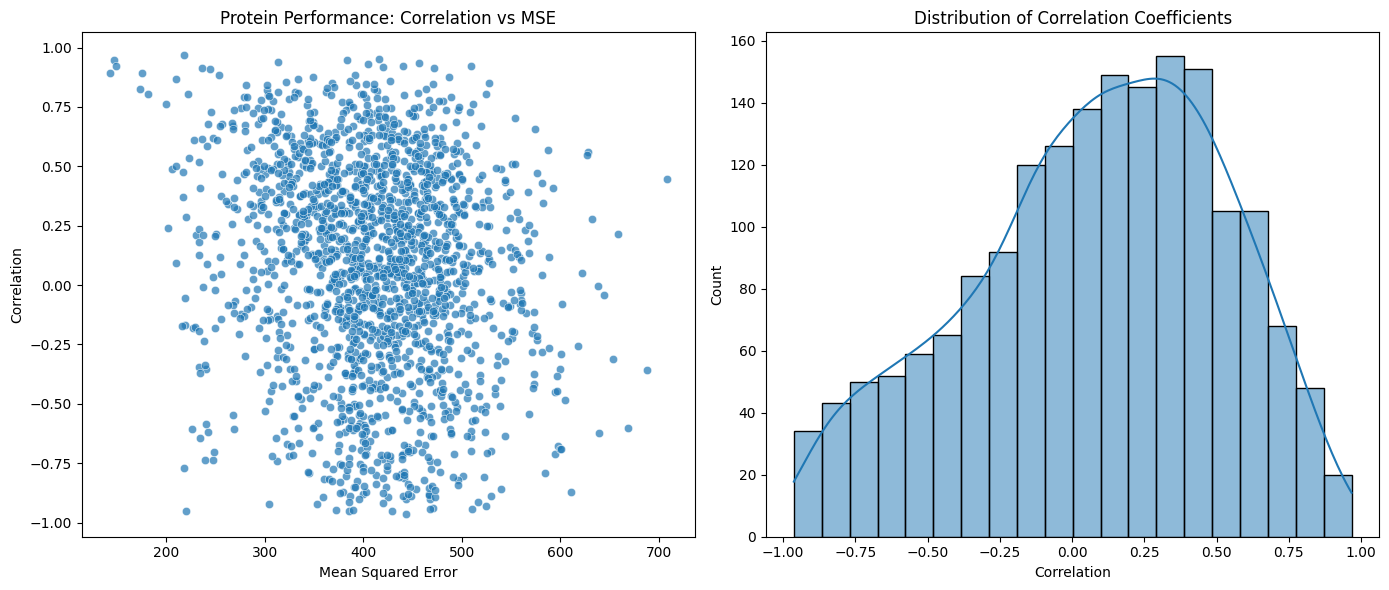

In [19]:

# 10. Global Visualizations

if 'results_df' in locals() and not results_df.empty:
    print("\n--- Global Performance Metrics ---\n")
    
    plt.figure(figsize=(14, 6))
    
    # 1. Correlation vs MSE Scatter
    plt.subplot(1, 2, 1)
    sns.scatterplot(data=results_df, x='MSE', y='Correlation', alpha=0.7)
    plt.title('Protein Performance: Correlation vs MSE')
    plt.xlabel('Mean Squared Error')
    plt.ylabel('Correlation')
    
    # 2. Correlation Distribution
    plt.subplot(1, 2, 2)
    sns.histplot(results_df['Correlation'], bins=20, kde=True)
    plt.title('Distribution of Correlation Coefficients')
    plt.xlabel('Correlation')
    
    plt.tight_layout()
    plt.show()



--- Tissue Performance Comparison ---



C:\Users\hp\AppData\Local\Temp\ipykernel_31296\3732386305.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=tissue_means.values, y=tissue_means.index, palette=colors)


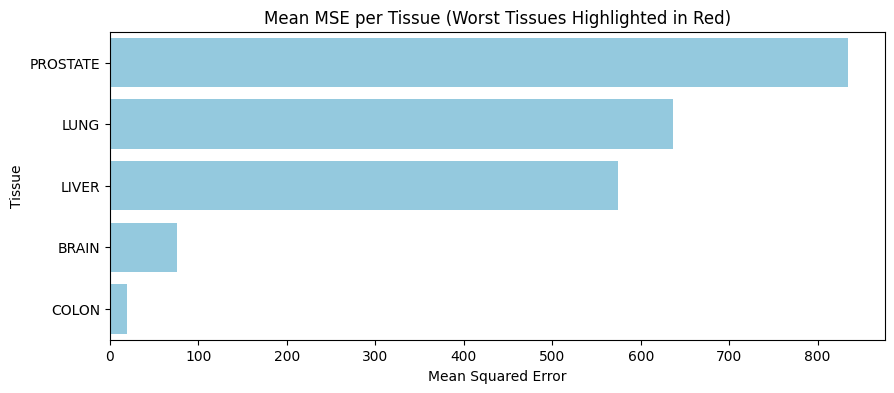

In [20]:

# 11. Tissue Performance Visualization
if 'tissue_df' in locals() and not tissue_df.empty:
    print("\n--- Tissue Performance Comparison ---\n")
    
    # Calculate mean MSE per tissue
    tissue_means = tissue_df.groupby("Tissue")["MSE"].mean().sort_values(ascending=False)
    
    plt.figure(figsize=(10, len(tissue_means) * 0.4 + 2))
    
    # Highlight worst tissues
    worst_targets = ['RENAL_2019', 'HEADNECK_2021', 'PANCREA2021']
    colors = ['red' if t in worst_targets else 'skyblue' for t in tissue_means.index]
    
    sns.barplot(x=tissue_means.values, y=tissue_means.index, palette=colors)
    plt.title("Mean MSE per Tissue (Worst Tissues Highlighted in Red)")
    plt.xlabel("Mean Squared Error")
    plt.show()
